# **Libraries and Dataset**

In [ ]:
!pip install ultralytics opencv-python numpy matplotlib -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 81.3 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
import zipfile
import shutil
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from ultralytics import YOLO
import cv2, numpy as np, yaml, tempfile

In [ ]:
drive.mount('/content/drive')


source_path = '/content/drive/MyDrive/Digital Signal/Kvasir.zip'
destination_path = '/content/dataset.zip'

shutil.copy(source_path, destination_path)
print(f'Copied {source_path} to {destination_path}')


# Unzip the file
with zipfile.ZipFile('/content/dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/data')
print('Extracted dataset.zip to /content/data')

# List contents of the extracted directory to verify
print('Contents of /content/ after extraction:')
print(os.listdir('/content/'))

Mounted at /content/drive
Copied /content/drive/MyDrive/Digital Signal/Kvasir.zip to /content/dataset.zip
Extracted dataset.zip to /content/data
Contents of /content/ after extraction:
['.config', 'data', 'dataset.zip', 'drive', 'sample_data']


# **U-Net Segmentation**

In [ ]:
# Config
DATA_DIR    = '/content/data/processed/unet'   # output of 01_preprocess.py
OUT_DIR     = '/content/data/processed/unet'
IMG_SIZE    = 256
BATCH_SIZE  = 8
EPOCHS      = 50
LR          = 1e-4
BASE_FILTERS = 32   # 32→64→128→256→512 channel progression

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
print(f"TensorFlow  {tf.__version__}")
print(f"GPUs        {tf.config.list_physical_devices('GPU')}")

TensorFlow  2.20.0
GPUs        [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Dataset

In [ ]:
def load_pair(img_path, mask_path):
    img  = tf.io.read_file(img_path)
    img  = tf.image.decode_jpeg(img, channels=3)
    img  = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img  = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, [IMG_SIZE, IMG_SIZE],
                           method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    mask = tf.cast(mask > 127, tf.float32)   # binarise → 0.0 / 1.0
    return img, mask


def build_dataset(img_dir, mask_dir, batch_size, shuffle=False):
    img_paths  = sorted(str(p) for p in Path(img_dir).glob('*.jpg'))
    mask_paths = [str(Path(mask_dir) / Path(p).with_suffix('.png').name)
                  for p in img_paths]
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    ds = ds.map(load_pair, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(img_paths), seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds, len(img_paths)


base = Path(DATA_DIR)
train_ds, n_train = build_dataset(base/'images/train', base/'masks/train',
                                   BATCH_SIZE, shuffle=True)
val_ds,   n_val   = build_dataset(base/'images/val',   base/'masks/val',   BATCH_SIZE)
test_ds,  n_test  = build_dataset(base/'images/test',  base/'masks/test',  BATCH_SIZE)

print(f"Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

Train: 2800  |  Val: 150  |  Test: 150


## Visualize Images

In [ ]:
def load_single_image_for_prediction(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.expand_dims(img, axis=0) # Add batch dimension
    return img

def find_corresponding_mask_for_image(test_mask_filename):
  test_mask_filename = Path(test_image_filename).with_suffix('.png').name
  full_ground_truth_mask_path = os.path.join(DATA_DIR, 'masks', 'test', test_mask_filename)
  return full_ground_truth_mask_path


def convert_to_gray_scale(original_image_data):
    if original_image_data.dtype == np.uint8:
      original_image_data = original_image_data.astype(np.float32) / 255.0

    if original_image_data.ndim == 3 and original_image_data.shape[-1] >= 3:
        gray_image_data = np.dot(original_image_data[..., :3], [0.2989, 0.5870, 0.1140])
    elif original_image_data.ndim == 2: # Already grayscale
        gray_image_data = original_image_data
    else:
        print("Warning: Original image is not 2D grayscale or 3D color. Using as is.")
        gray_image_data = original_image_data

    return gray_image_data

def load_mask_image(full_mask_image_path):
    ground_truth_mask_data = plt.imread(full_ground_truth_mask_path)
    if ground_truth_mask_data.ndim == 3 and ground_truth_mask_data.shape[-1] >= 3:
        ground_truth_mask_data = ground_truth_mask_data[..., 0] # Take one channel if it's RGB/RGBA

    return ground_truth_mask_data

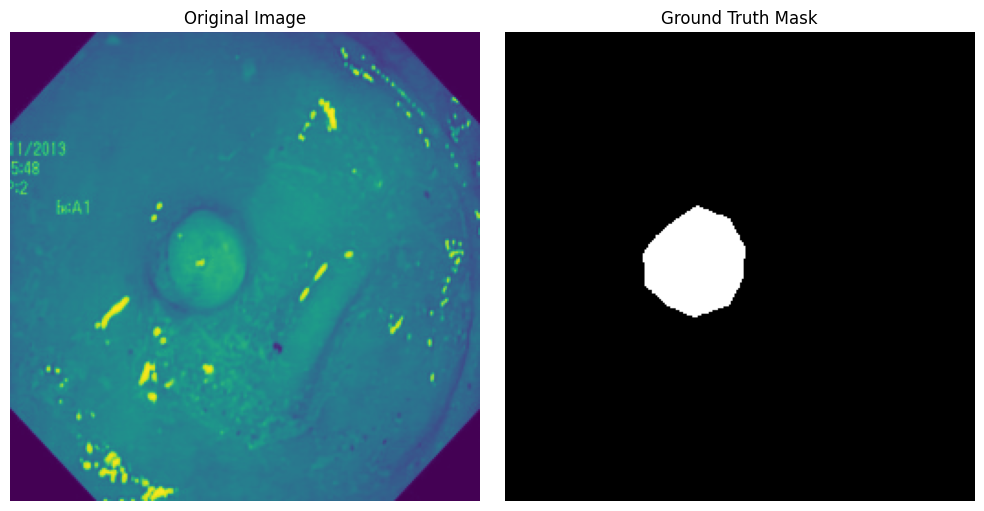

In [ ]:

image_path_for_prediction = '/content/data/processed/unet/images/test/cju1euuc65wm00799m4sjdnnn.jpg'

# Test image and coresponding ground truth image
test_image_filename = Path(image_path_for_prediction).name
full_ground_truth_mask_path = find_corresponding_mask_for_image(Path(test_image_filename).with_suffix('.png').name)

# Load and preprocess the image for prediction
preprocessed_image = load_single_image_for_prediction(image_path_for_prediction)

# Load the ground truth mask for the test image
ground_truth_mask_data = load_mask_image(full_ground_truth_mask_path)

# Display the original image, ground truth mask, and predicted mask
plt.figure(figsize=(15, 5)) # Adjusted figure size for three plots

plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
plt.title("Original Image")
plt.imshow(convert_to_gray_scale(preprocessed_image[0]))
plt.axis('off')

plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
plt.title('Ground Truth Mask')
plt.imshow(ground_truth_mask_data, cmap='gray')
plt.axis('off')


plt.tight_layout()
plt.show()

## U-Net Architecture

In [ ]:
def double_conv_block(x, filters):
    """Two Conv2D–BatchNorm–ReLU layers."""
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def encoder_block(x, filters):
    """Double conv → skip + max-pool down."""
    skip = double_conv_block(x, filters)
    down = layers.MaxPooling2D(2)(skip)
    return skip, down

def decoder_block(x, skip, filters):
    """Transpose conv up → concat skip → double conv."""
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding='same')(x)
    x = layers.Concatenate()([x, skip])
    x = double_conv_block(x, filters)
    return x

def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=BASE_FILTERS):
    f = base_filters
    inputs = keras.Input(shape=input_shape, name='image')

    s1, d1 = encoder_block(inputs, f)
    s2, d2 = encoder_block(d1,     f*2)
    s3, d3 = encoder_block(d2,     f*4)
    s4, d4 = encoder_block(d3,     f*8)

    b = double_conv_block(d4, f*16)  # bottleneck

    u4 = decoder_block(b,  s4, f*8)
    u3 = decoder_block(u4, s3, f*4)
    u2 = decoder_block(u3, s2, f*2)
    u1 = decoder_block(u2, s1, f)

    outputs = layers.Conv2D(1, 1, activation='sigmoid', name='mask')(u1)
    return Model(inputs, outputs, name='UNet')

model = build_unet()
model.summary(line_length=80)

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)    │ (None, 256, 256,  │           0 │ -                  │
│                       │ 3)                │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d (Conv2D)       │ (None, 256, 256,  │         864 │ image[0][0]        │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization   │ (None, 256, 256,  │         128 │ conv2d[0][0]       │
│ (BatchNormalization)  │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ activation            │ (None, 256, 256,  │           0 │ batch_normalizati… │
│ (Activation)          │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_1 (Conv2D)     │ (None, 256, 256,  │       9,216 │ activation[0][0]   │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_1 │ (None, 256, 256,  │         128 │ conv2d_1[0][0]     │
│ (BatchNormalization)  │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ activation_1          │ (None, 256, 256,  │           0 │ batch_normalizati… │
│ (Activation)          │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ max_pooling2d         │ (None, 128, 128,  │           0 │ activation_1[0][0] │
│ (MaxPooling2D)        │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_2 (Conv2D)     │ (None, 128, 128,  │      18,432 │ max_pooling2d[0][… │
│                       │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_2 │ (None, 128, 128,  │         256 │ conv2d_2[0][0]     │
│ (BatchNormalization)  │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ activation_2          │ (None, 128, 128,  │           0 │ batch_normalizati… │
│ (Activation)          │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_3 (Conv2D)     │ (None, 128, 128,  │      36,864 │ activation_2[0][0] │
│                       │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_3 │ (None, 128, 128,  │         256 │ conv2d_3[0][0]     │
│ (BatchNormalization)  │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ activation_3          │ (None, 128, 128,  │           0 │ batch_normalizati… │
│ (Activation)          │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ max_pooling2d_1       │ (None, 64, 64,    │           0 │ activation_3[0][0] │
│ (MaxPooling2D)        │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_4 (Conv2D)     │ (None, 64, 64,    │      73,728 │ max_pooling2d_1[0… │
│                       │ 128) 

 Total params: 7,768,929 (29.64 MB)

 Trainable params: 7,763,041 (29.61 MB)

 Non-trainable params: 5,888 (23.00 KB)

## Loss and Metrics

In [ ]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    inter    = tf.reduce_sum(y_true_f * y_pred_f)
    return 1.0 - (2.0*inter + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    """BCE×0.5 + Dice×0.5 — best combination for small polyp regions."""
    bce = tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred))
    return 0.5 * bce + 0.5 * dice_loss(y_true, y_pred)

def dice_coeff(y_true, y_pred, threshold=0.5, smooth=1e-6):
    y_pred_bin = tf.cast(y_pred > threshold, tf.float32)
    y_true_f   = tf.reshape(y_true,     [-1])
    y_pred_f   = tf.reshape(y_pred_bin, [-1])
    inter      = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0*inter + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou_coeff(y_true, y_pred, threshold=0.5, smooth=1e-6):
    y_pred_bin = tf.cast(y_pred > threshold, tf.float32)
    y_true_f   = tf.reshape(y_true,     [-1])
    y_pred_f   = tf.reshape(y_pred_bin, [-1])
    inter      = tf.reduce_sum(y_true_f * y_pred_f)
    union      = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + smooth) / (union + smooth)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss=bce_dice_loss,
    metrics=[dice_coeff, iou_coeff],
)
print("Model compiled.")

Model compiled.


## Callbacks

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=f'{OUT_DIR}/best_model.keras',
        monitor='val_dice_coeff',
        mode='max',
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_dice_coeff', mode='max',
        factor=0.5, patience=5, min_lr=1e-7, verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_dice_coeff', mode='max',
        patience=15, restore_best_weights=True, verbose=1,
    ),
]

# Optional: add TensorBoard only if it is installed
try:
    import tensorboard  # noqa: F401
    callbacks.append(
        keras.callbacks.TensorBoard(log_dir=f'{OUT_DIR}/logs', histogram_freq=0)
    )
    print("TensorBoard callback enabled.")
except ImportError:
    print("TensorBoard not installed — skipping that callback (training unaffected).")

print(f"Active callbacks: {[type(c).__name__ for c in callbacks]}")

TensorBoard callback enabled.
Active callbacks: ['ModelCheckpoint', 'ReduceLROnPlateau', 'EarlyStopping', 'TensorBoard']


## Train

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)
model.save(f'{OUT_DIR}/last_model.keras')
print(f"last_model.keras saved to {OUT_DIR}/")

Epoch 1/50
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - dice_coeff: 0.4625 - iou_coeff: 0.3116 - loss: 0.5432
Epoch 1: val_dice_coeff improved from None to 0.27402, saving model to /content/data/processed/unet/best_model.keras

Epoch 1: finished saving model to /content/data/processed/unet/best_model.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 69s 101ms/step - dice_coeff: 0.5385 - iou_coeff: 0.3769 - loss: 0.4869 - val_dice_coeff: 0.2740 - val_iou_coeff: 0.1632 - val_loss: 0.5692 - learning_rate: 1.0000e-04
Epoch 2/50
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - dice_coeff: 0.6372 - iou_coeff: 0.4746 - loss: 0.3921
Epoch 2: val_dice_coeff improved from 0.27402 to 0.70629, saving model to /content/data/processed/unet/best_model.keras

Epoch 2: finished saving model to /content/data/processed/unet/best_model.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - dice_coeff: 0.6563 - iou_coeff: 0.4955 - loss: 0.3714 - val_dice_coeff: 0.7063 - val_iou_coeff: 0.5507 - val_loss: 0.3338 - learning_rate: 1.0

## Training Curves

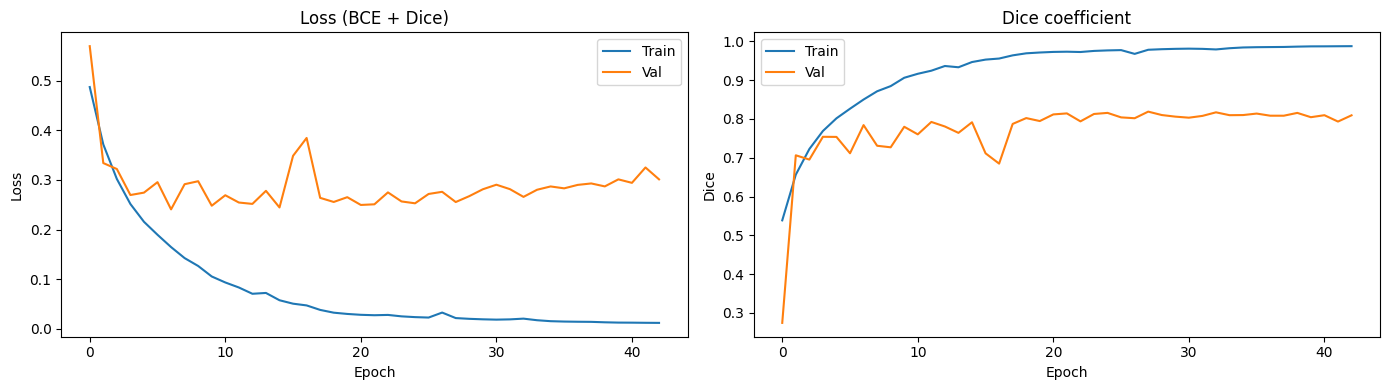

Curves saved to /content/data/processed/unet/training_curves.png


In [ ]:
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(h['loss'],          label='Train', linewidth=1.5)
axes[0].plot(h['val_loss'],      label='Val',   linewidth=1.5)
axes[0].set_title('Loss (BCE + Dice)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(h['dice_coeff'],     label='Train', linewidth=1.5)
axes[1].plot(h['val_dice_coeff'], label='Val',   linewidth=1.5)
axes[1].set_title('Dice coefficient')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Dice')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150)
plt.show()
print(f"Curves saved to {OUT_DIR}/training_curves.png")

## Test set evaluation

In [ ]:
best_model = keras.models.load_model(
    f'{OUT_DIR}/best_model.keras',
    custom_objects={
        'bce_dice_loss': bce_dice_loss,
        'dice_coeff':    dice_coeff,
        'iou_coeff':     iou_coeff,
    },
)
results     = best_model.evaluate(test_ds, verbose=1)
metric_names = ['loss', 'dice_coeff', 'iou_coeff']
result_dict  = dict(zip(metric_names, results))

print(f"\nTest Loss : {result_dict['loss']:.4f}")
print(f"Test Dice : {result_dict['dice_coeff']:.4f}")
print(f"Test IoU  : {result_dict['iou_coeff']:.4f}")

with open(f'{OUT_DIR}/test_metrics.txt', 'w') as f:
    for k, v in result_dict.items():
        f.write(f'{k}: {v:.4f}\n')
print(f"Metrics saved to {OUT_DIR}/test_metrics.txt")

19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - dice_coeff: 0.8008 - iou_coeff: 0.6726 - loss: 0.2743

Test Loss : 0.2743
Test Dice : 0.8008
Test IoU  : 0.6726
Metrics saved to /content/data/processed/unet/test_metrics.txt


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


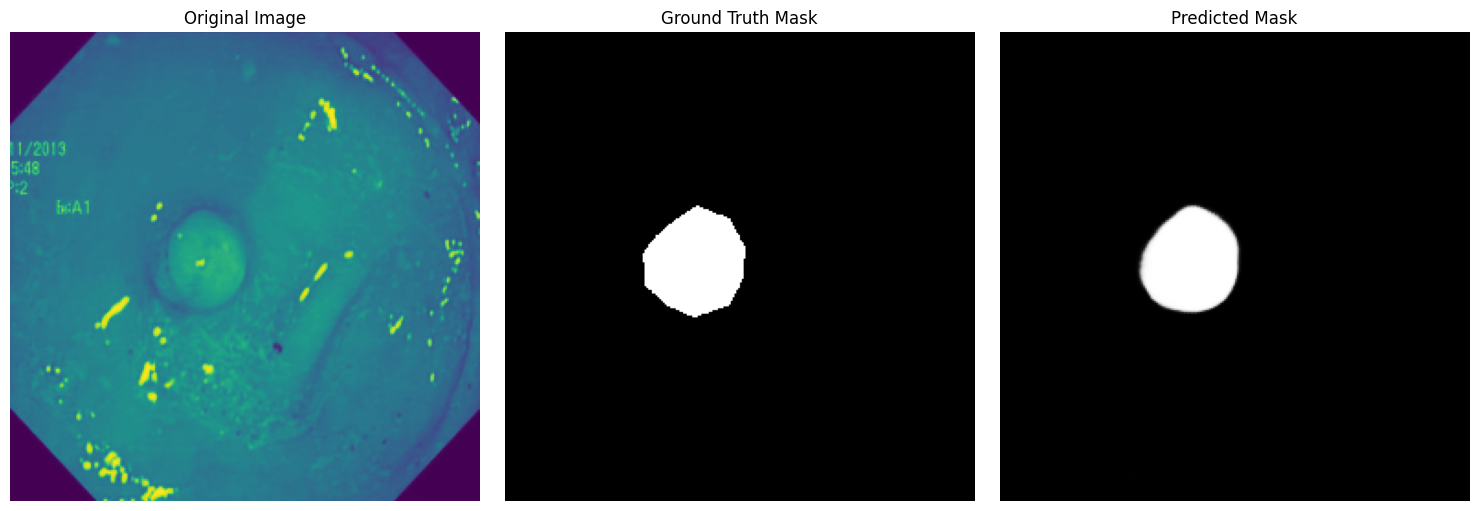

In [ ]:

# Derive the corresponding ground truth mask path for the test image
# Assuming mask files have the same name as images but with .png extension
test_image_filename = Path(image_path_for_prediction).name
test_mask_filename = Path(test_image_filename).with_suffix('.png').name
full_ground_truth_mask_path = os.path.join(DATA_DIR, 'masks', 'test', test_mask_filename)

# Load and preprocess the image for prediction
preprocessed_image = load_single_image_for_prediction(image_path_for_prediction)
predicted_mask = best_model.predict(preprocessed_image)

# Load the ground truth mask for the test image
ground_truth_mask_data = plt.imread(full_ground_truth_mask_path)
if ground_truth_mask_data.ndim == 3 and ground_truth_mask_data.shape[-1] >= 3:
    ground_truth_mask_data = ground_truth_mask_data[..., 0] # Take one channel if it's RGB/RGBA

# Display the original image, ground truth mask, and predicted mask
plt.figure(figsize=(15, 5)) # Adjusted figure size for three plots

plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
plt.title("Original Image")
plt.imshow(convert_to_gray_scale(preprocessed_image[0]))
plt.axis('off')

plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
plt.title('Ground Truth Mask')
plt.imshow(ground_truth_mask_data, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
plt.title("Predicted Mask")
plt.imshow(predicted_mask[0, :, :, 0], cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()